# **Deel 1 - Les 4 - Oefening**

**Doel van de oefening:**
We bouwen een eenvoudige **Machine Learning Pipeline** om te voorspellen hoeveel koppen koffie een student consumeert.

**Onderwerpen in deze oefening:**
- **Preprocessing**: Imputatie (`SimpleImputer`), Schalen (`RobustScaler`), One-Hot & Ordinal Encoding, en Polynomiale interacties (`PolynomialFeatures`).
- **Regularisatie**: Oplossen van overfitting met L1 (`Lasso`) en L2 (`Ridge`).
- **Hyperparameter Tuning**: Automatisch optimaliseren via `GridSearchCV`.
- **Evaluatie**: RMSE, \(R^2\) en residual diagnostics.

## Stap 1: Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
import os

## Stap 2: Data

In [2]:
df_koffie_consumptie = pd.read_csv('student_koffie_consumptie.csv')
display(df_koffie_consumptie.head())
df_koffie_consumptie.info()

,slaap_uren,open_tabs,uitstel_uren,studie_richting,deadline_druk,koppen_koffie
0,5.1,35,2.1,Informatica,Laag,5.7
1,9.2,21,0.3,Geneeskunde,Laag,0.0
2,7.6,16,1.8,Filosofie,Hoog,2.5
3,6.7,52,5.8,Informatica,Hoog,9.2
4,NaN,7,4.2,Filosofie,Hoog,7.4


<class 'pandas.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   slaap_uren       428 non-null    float64
 1   open_tabs        450 non-null    int64  
 2   uitstel_uren     436 non-null    float64
 3   studie_richting  450 non-null    str    
 4   deadline_druk    450 non-null    str    
 5   koppen_koffie    450 non-null    float64
dtypes: float64(3), int64(1), str(2)
memory usage: 21.2 KB


|kolom|feature|null|type|Beschrijving|
|:---|:---|:---|:---|:---|  
|0|slaap_uren|428 non-null|float64|verwijst naar het aantal uren slaap per nacht|
|1|open_tabs|450 non-null|int64|verwijst naar het aantal geopende tabbladen in de webbrowser van de student|
|2|uitstel_uren|436 non-null|float64|verwijst naar het aantal uren dat de student uitstelgedrag vertoont bij het uitvoeren van taken|
|3|studie_richting|450 non-null|object|verwijst naar de studierichting van de student (bijvoorbeeld "Informatica", "Economie", "Psychologie", enz.)|
|4|deadline_druk|450 non-null|object|verwijst naar de mate van druk die de student ervaart bij het halen van deadlines (bijvoorbeeld "Laag", "Gemiddeld", "Hoog")|
|5|koppen_koffie|450 non-null|int64|verwijst naar het aantal koppen koffie dat de student per dag drinkt|

## Stap 3: Preprocessing

1. **Numerieke features**: Imputeren van mediaan \(\rightarrow\) `RobustScaler` (bestand tegen extreme tabs) \(\rightarrow\) optionele polynomiale interacties.
2. **Ordinale features**: Imputeren van modus \(\rightarrow\) `OrdinalEncoder` met expliciete rangorde.
3. **Nominale features**: `OneHotEncoder` (met `drop='first'` en `handle_unknown='ignore'`).

In [3]:
# Featuregroepen en target
numerieke_features = ['slaap_uren', 'open_tabs', 'uitstel_uren']
ordinale_features = ['deadline_druk']
nominale_features = ['studie_richting']
target = 'koppen_koffie'

# Numerieke preprocessing: ontbrekende waarden -> mediaan, robuust schalen,
# daarna optioneel polynomiale/interactietermen (degree wordt later getuned).
numerieke_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
    ('poly', PolynomialFeatures(degree=1, include_bias=False))
])

# Deadline-druk heeft een natuurlijke rangorde.
ordinale_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(
        categories=[['Laag', 'Matig', 'Hoog', 'Apocalyptisch']],
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# Studierichting is nominaal: geen rangorde, dus one-hot encoding.
nominale_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerieke_pipeline, numerieke_features),
    ('ord', ordinale_pipeline, ordinale_features),
    ('nom', nominale_pipeline, nominale_features)
])

## Stap 4: Splitsen in Train en Test

In [4]:
X = df_koffie_consumptie.drop(columns=target)
y = df_koffie_consumptie[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Omvang trainingset: {X_train.shape[0]} | Omvang testset: {X_test.shape[0]}")

Omvang trainingset: 360 | Omvang testset: 90


## Stap 5: ML Pipeline

### Stap 5.1: Baseline ML Pipeline

In [5]:
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

### Stap 6.1: Baseline Training

In [6]:
baseline_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

### Stap 7.1: Baseline Evaluatie

In [7]:
y_pred_base = baseline_pipeline.predict(X_test)
print(f"--- Baseline Linear Regression ---")
print(f"R² Score: {r2_score(y_test, y_pred_base):.3f}")
print(f"RMSE:     {np.sqrt(mean_squared_error(y_test, y_pred_base)):.3f}")

--- Baseline Linear Regression ---
R² Score: 0.856
RMSE:     1.278


### Stap 5.2: ML Pipeline met regularisatie en hyperparameter tuning

We testen interactietermen (`poly__degree` = 1 of 2) en optimaliseren de regularisatie-sterkte (`alpha`).
- **Ridge (L2)**: Verkleint gewichten (handig bij multicollineariteit tussen polynomiale termen).
- **Lasso (L1)**: Zet irrelevante coëfficiënten exact op 0 (automatische feature selectie).

In [8]:
# We maken een template pipeline met een instelbare estimator
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

# Param grid: we vergelijken zowel Ridge als Lasso over verschillende alpha-waarden
# en polynomiale graden. Elke dictionary bevat alleen geldige parameters voor dat model.
param_grid = [
    {
        'preprocessor__num__poly__degree': [1, 2],
        'model': [Ridge(max_iter=10000)],
        'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
    },
    {
        'preprocessor__num__poly__degree': [1, 2],
        'model': [Lasso(max_iter=10000)],
        'model__alpha': [0.001, 0.01, 0.1, 1.0, 10.0]
    }
]

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1
)

### Stap 6.2: Training met regularisatie en hyperparameter tuning

In [9]:
grid_search.fit(X_train, y_train)

print(f"Beste Model Score (negatieve CV MSE): {grid_search.best_score_:.3f}")
print("Beste Hyperparameters:")
for param, val in grid_search.best_params_.items():
    print(f" - {param}: {val}")

Beste Model Score (negatieve CV MSE): -0.909
Beste Hyperparameters:
 - model: Ridge(max_iter=10000)
 - model__alpha: 0.01
 - preprocessor__num__poly__degree: 2


### Stap 7.2: Evaluatie met regularisatie en hyperparameter tuning

In [10]:
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

final_r2 = r2_score(y_test, y_pred_best)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_best))

print("=== DEFINITIEVE TEST EVALUATIE ===")
print(f"Eind R² Score: {final_r2:.3f}")
print(f"Eind RMSE:     {final_rmse:.3f} koppen koffie")

=== DEFINITIEVE TEST EVALUATIE ===
Eind R² Score: 0.860
Eind RMSE:     1.262 koppen koffie


## Stap 7: Evaluatie

In [11]:
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
coefficients = best_model.named_steps['model'].coef_

coeff_df = pd.DataFrame({
    'Feature': feature_names,
    'Coëfficiënt': coefficients
}).sort_values(by='Coëfficiënt', key=abs, ascending=False)

display(coeff_df)

,Feature,Coëfficiënt
0,num__slaap_uren,-3.798899
2,num__uitstel_uren,2.484779
10,nom__studie_richting_Geneeskunde,2.138238
9,ord__deadline_druk,1.805247
11,nom__studie_richting_Informatica,1.493326
12,nom__studie_richting_Rechten,1.012690
5,num__slaap_uren uitstel_uren,-0.883984
1,num__open_tabs,0.632335
8,num__uitstel_uren^2,0.175635
4,num__slaap_uren open_tabs,0.089850


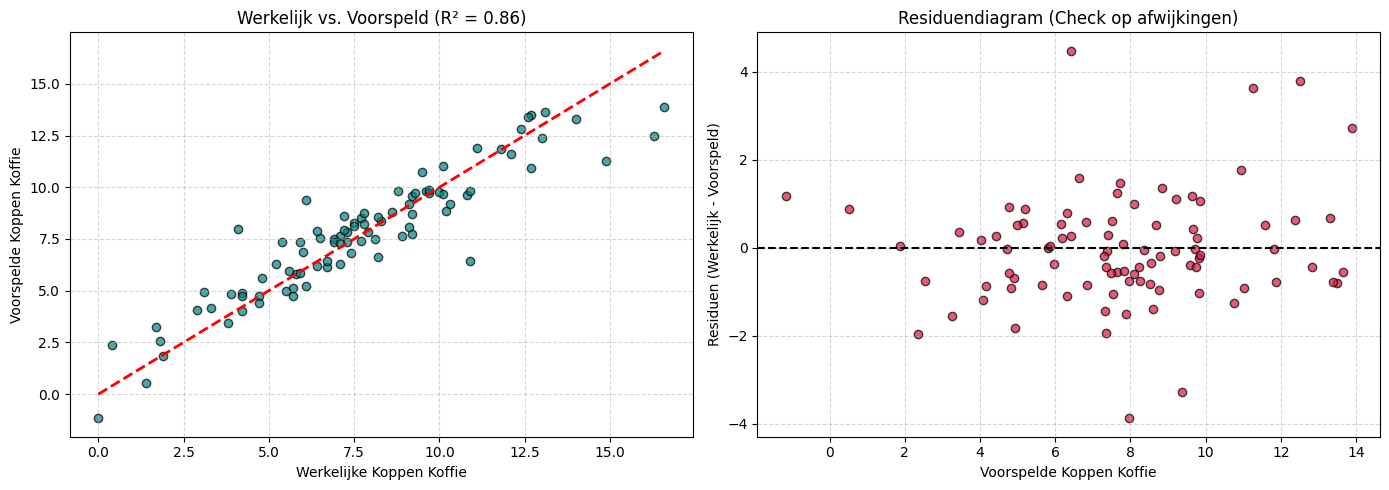

In [12]:
# Visualisatie: Werkelijk vs Voorspeld & Residuen
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Voorspeld vs Werkelijk
axes[0].scatter(y_test, y_pred_best, alpha=0.7, color='teal', edgecolors='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel("Werkelijke Koppen Koffie")
axes[0].set_ylabel("Voorspelde Koppen Koffie")
axes[0].set_title(f"Werkelijk vs. Voorspeld (R² = {final_r2:.2f})")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Residu plot (Homoscedasticiteit check)
residuals = y_test - y_pred_best
axes[1].scatter(y_pred_best, residuals, alpha=0.7, color='crimson', edgecolors='k')
axes[1].axhline(y=0, color='black', linestyle='--')
axes[1].set_xlabel("Voorspelde Koppen Koffie")
axes[1].set_ylabel("Residuen (Werkelijk - Voorspeld)")
axes[1].set_title("Residuendiagram (Check op afwijkingen)")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Stap 8: Predictie

In [13]:
nieuwe_studenten = pd.DataFrame([
    {
        'slaap_uren': 3.0,
        'open_tabs': 85,
        'uitstel_uren': 7.5,
        'studie_richting': 'Informatica',
        'deadline_druk': 'Apocalyptisch'
    },
    {
        'slaap_uren': np.nan, # Vergeten in te vullen door uitputting
        'open_tabs': 12,
        'uitstel_uren': 1.0,
        'studie_richting': 'Filosofie',
        'deadline_druk': 'Laag'
    }
])

voorspellingen = best_model.predict(nieuwe_studenten)

for idx, p in enumerate(voorspellingen):
    print(f"Student {idx+1} ({nieuwe_studenten.iloc[idx]['studie_richting']}): "
          f"Verwacht cafeïneverbruik = {p:.1f} koppen koffie/dag.")

Student 1 (Informatica): Verwacht cafeïneverbruik = 16.8 koppen koffie/dag.
Student 2 (Filosofie): Verwacht cafeïneverbruik = 1.1 koppen koffie/dag.
